# ARTI403: Image Processing
## Lab 6: Frequency Domain

**Student Name:** Saad Abdulaziz Alshehri  
**Student ID:** 2240006495


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, ifftshift
from skimage import data
from skimage.transform import resize

os.makedirs('images', exist_ok=True)
%matplotlib inline

# Section 3: Procedural Steps
## Task 1: Filtering in the Frequency Domain (Laplacian)

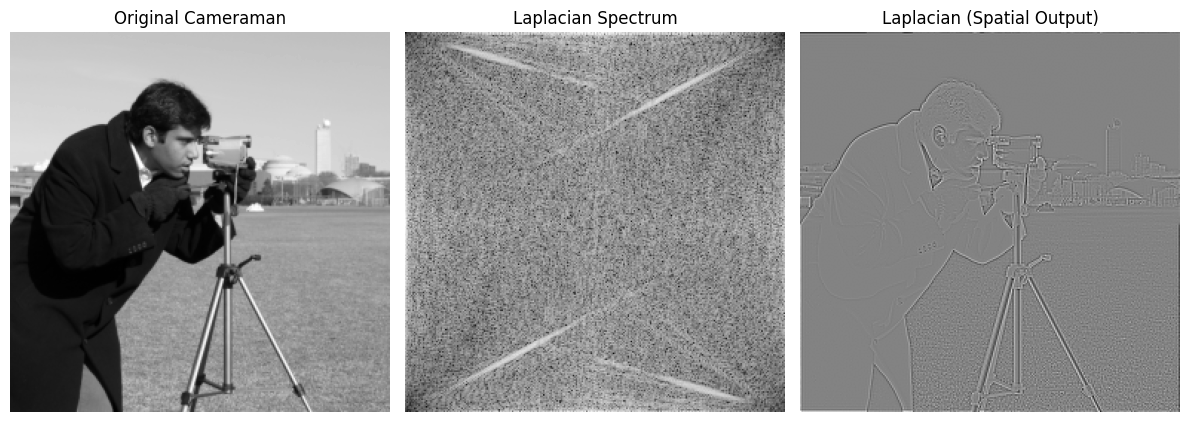

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
cv2.imwrite('images/cameraman.png', image)
image = resize(image, (256, 256))  # Resize for faster FFT

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')
plt.tight_layout()
plt.savefig('images/task1_laplacian_frequency.png', dpi=120, bbox_inches='tight')
plt.show()

# Section 4: Assessment
## Task 1: Sobel filters in the frequency domain (cameraman image)

In [3]:
# Load and resize image (same as the procedural task)
image = resize(data.camera(), (256, 256))

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters (use the provided function)
Sx = center_embed_kernel(sobel_x, image.shape)
Sy = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain, then go back to the spatial domain
Gx = ifft2(F * Sx).real
Gy = ifft2(F * Sy).real
magnitude = np.sqrt(Gx**2 + Gy**2)

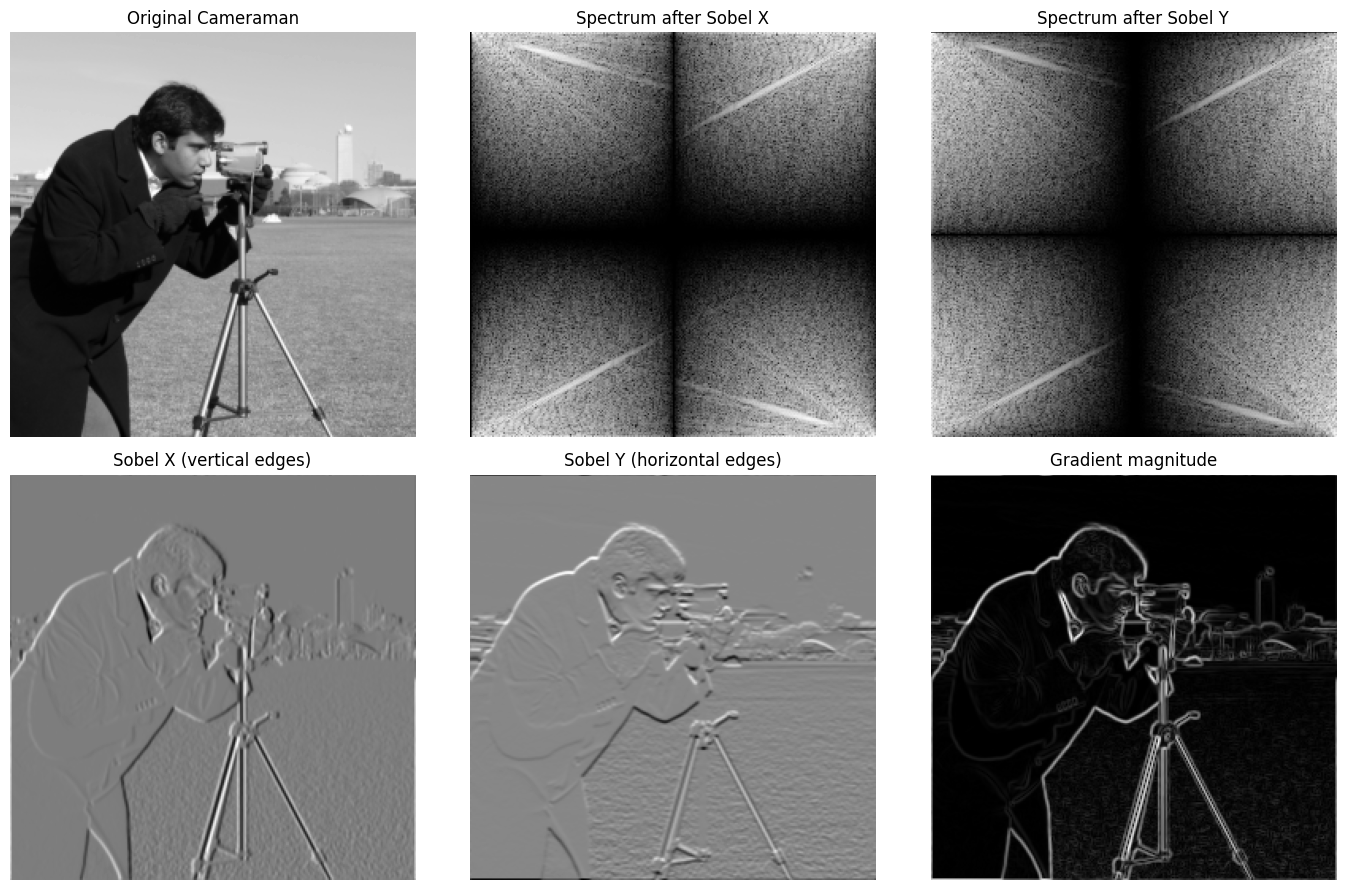

In [4]:
# Plot
fig, ax = plt.subplots(2, 3, figsize=(14, 9))
ax[0, 0].imshow(image, cmap='gray')
ax[0, 0].set_title('Original Cameraman')
ax[0, 1].imshow(np.log(1 + np.abs(F * Sx)), cmap='gray')
ax[0, 1].set_title('Spectrum after Sobel X')
ax[0, 2].imshow(np.log(1 + np.abs(F * Sy)), cmap='gray')
ax[0, 2].set_title('Spectrum after Sobel Y')
ax[1, 0].imshow(Gx, cmap='gray')
ax[1, 0].set_title('Sobel X (vertical edges)')
ax[1, 1].imshow(Gy, cmap='gray')
ax[1, 1].set_title('Sobel Y (horizontal edges)')
ax[1, 2].imshow(magnitude, cmap='gray')
ax[1, 2].set_title('Gradient magnitude')
for a in ax.flat:
    a.axis('off')
plt.tight_layout()
plt.savefig('images/assessment1_sobel_frequency.png', dpi=120, bbox_inches='tight')
plt.show()